In [6]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import mannwhitneyu


# ============================================================
# FINAL CATBOOST EVALUATION
# FROZEN OPTUNA CONFIGURATION + FULL LOGO-CV
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ============================================================
# 2. DATA PREPARATION
# ============================================================

# Convert target to numeric
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

# Target and organization ID must NOT be predictors.
# Project ID is also excluded if present.

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Keep only categorical columns that actually exist
nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical values to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost categorical feature indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

# Same transformation used during tuning
y_log = np.log1p(y)


# ============================================================
# 7. LOGO VALIDATION SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_groups = groups.nunique()


print("=" * 65)
print("        FINAL CATBOOST LOGO EVALUATION")
print("=" * 65)

print(f"Observations:       {len(X)}")
print(f"Organizations:      {n_groups}")
print(f"Features:           {X.shape[1]}")
print(f"Categorical:        {len(cat_indices)}")
print("Validation:         Leave-One-Organization-Out")
print(f"Expected folds:     {n_groups}")


# ============================================================
# 8. FROZEN OPTUNA CONFIGURATION
# ============================================================

# Trial 11 — BEST OPTUNA CONFIGURATION

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


print("\n" + "-" * 65)
print("FROZEN OPTUNA PARAMETERS")
print("-" * 65)

for name, value in final_params.items():
    print(f"{name:<22}: {value}")


# ============================================================
# 9. STORAGE FOR OUT-OF-FOLD PREDICTIONS
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FULL LOGO CROSS-VALIDATION
# ============================================================

print("\n")
print("Starting final LOGO evaluation...")
print()


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split data
    # --------------------------------------------------------

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train_log = y_log.iloc[train_idx]

    true = y.iloc[test_idx].to_numpy()


    # --------------------------------------------------------
    # Create CatBoost model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        # FROZEN OPTUNA PARAMETERS
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],

        # Model settings
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,

        # Use all available CPU threads
        thread_count=-1,

        # No training output
        verbose=False,

        # Prevent CatBoost from creating extra files
        allow_writing_files=False
    )


    # --------------------------------------------------------
    # Train on all organizations EXCEPT the held-out one
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train_log
    )


    # --------------------------------------------------------
    # Predict the held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )


    # Convert prediction back from log scale
    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store detailed project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre_value = (
            absolute_error / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[original_idx],
            'Actual_Effort': actual,
            'Predicted_Effort': predicted,
            'Absolute_Error': absolute_error,
            'MRE': mre_value
        })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"Fold {fold:>2}/{n_groups} completed"
    )


# ============================================================
# 11. CONVERT ALL PREDICTIONS TO ARRAYS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# ============================================================
# 12. CALCULATE MRE
# ============================================================

mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# ============================================================
# 13. FINAL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(
    mre
)

mdmre = np.median(
    mre
)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 14. STANDARDIZED ACCURACY (Shepperd & MacDonell, 2012)
#     + SIGNIFICANCE TEST AGAINST RANDOM GUESSING
# ============================================================

# SA compares model MAE against the MAE of random guessing, where
# "random guessing" means: for each project, guess the actual effort
# of a different, randomly chosen project from the same evaluation
# set. This is NOT the same as guessing the mean effort — the mean
# is already a fairly strong naive predictor, so using it as the
# baseline understates the baseline's difficulty and inflates SA.
# The baseline is estimated by averaging many random-guess runs.

n_projects = len(y_true_arr)

rng = np.random.default_rng(RANDOM_SEED)

n_bootstraps = 1000


def random_guess_indices(n, rng):

    idx = rng.integers(0, n, size=n)

    same = idx == np.arange(n)

    while same.any():
        idx[same] = rng.integers(0, n, size=same.sum())
        same = idx == np.arange(n)

    return idx


random_maes = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_projects,
        rng
    )

    random_maes[b] = mean_absolute_error(
        y_true_arr,
        y_true_arr[guess_idx]
    )

random_guess_mae = random_maes.mean()

sa = (
    1 - mae / random_guess_mae
) * 100


# --------------------------------------------------------
# Significance test: is the model significantly better than
# random guessing? Mann-Whitney U test on the absolute-error
# distributions, plus the Â12 effect size.
# --------------------------------------------------------

model_ae = np.abs(
    y_true_arr - y_pred_arr
)

guess_idx = random_guess_indices(
    n_projects,
    rng
)

random_ae = np.abs(
    y_true_arr - y_true_arr[guess_idx]
)

u_stat, p_value = mannwhitneyu(
    model_ae,
    random_ae,
    alternative='less'
)

a12 = u_stat / (
    len(model_ae) * len(random_ae)
)


print("\n" + "=" * 65)
print("       STANDARDIZED ACCURACY (SA)")
print("=" * 65)

print(
    f"Random-guess MAE:  {random_guess_mae:.2f} hours "
    f"(mean of {n_bootstraps} bootstraps)"
)

print(
    f"SA:                {sa:.2f}%"
)

print(
    f"Mann-Whitney p:    {p_value:.4g}  "
    "(model AE < random-guess AE)"
)

print(
    f"Â12 effect size:   {a12:.3f}  "
    "(>0.5 = model beats chance more often than not)"
)


# ============================================================
# 15. SENSITIVITY ANALYSIS — EXCLUDING MRE > 100% OUTLIERS
# ============================================================

low_mre_mask = mre <= 1.0

y_true_clean = y_true_arr[low_mre_mask]
y_pred_clean = y_pred_arr[low_mre_mask]
mre_clean = mre[low_mre_mask]

n_clean = len(y_true_clean)

mae_clean = mean_absolute_error(
    y_true_clean,
    y_pred_clean
)

model_ae_clean = np.abs(
    y_true_clean - y_pred_clean
)

random_maes_clean = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_clean,
        rng
    )

    random_maes_clean[b] = mean_absolute_error(
        y_true_clean,
        y_true_clean[guess_idx]
    )

random_guess_mae_clean = random_maes_clean.mean()

sa_clean = (
    1 - mae_clean / random_guess_mae_clean
) * 100

guess_idx_clean = random_guess_indices(
    n_clean,
    rng
)

random_ae_clean = np.abs(
    y_true_clean - y_true_clean[guess_idx_clean]
)

u_stat_clean, p_value_clean = mannwhitneyu(
    model_ae_clean,
    random_ae_clean,
    alternative='less'
)

a12_clean = u_stat_clean / (
    len(model_ae_clean) * len(random_ae_clean)
)


print("\n" + "=" * 65)
print("       SENSITIVITY ANALYSIS — EXCLUDING MRE > 100%")
print("=" * 65)

print(
    f"Projects evaluated:  {n_clean} / {n_projects}"
)

print(
    f"MAE:                 {mae_clean:.2f} hours"
)

print(
    f"MMRE:                {np.mean(mre_clean):.4f} "
    f"({np.mean(mre_clean) * 100:.2f}%)"
)

print(
    f"MdMRE:               {np.median(mre_clean):.4f} "
    f"({np.median(mre_clean) * 100:.2f}%)"
)

print(
    f"PRED(25):            {np.mean(mre_clean <= 0.25) * 100:.2f}%"
)

print(
    f"SA:                  {sa_clean:.2f}%"
)

print(
    f"Mann-Whitney p:      {p_value_clean:.4g}"
)

print(
    f"Â12 effect size:     {a12_clean:.3f}"
)


# ============================================================
# 16. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("       FINAL CATBOOST LOGO-CV RESULTS")
print("=" * 65)

print(
    f"MAE:       {mae:.2f} hours"
)

print(
    f"R²:        {r2:.4f}"
)

print(
    f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):  {pred25 * 100:.2f}%"
)

print(
    f"SA:        {sa:.2f}%"
)

print("=" * 65)


# ============================================================
# 17. PROJECT-LEVEL PREDICTION TABLE
# ============================================================

predictions_df = pd.DataFrame(
    prediction_records
)


print("\nProject-level predictions created.")
print(
    f"Number of predictions: {len(predictions_df)}"
)

print("\nFirst 10 predictions:")
print(
    predictions_df.head(10)
)

KeyError: 'Effort_Actual effort'

In [7]:
# 1. تسطيح عناوين الأعمدة إذا كانت MultiIndex
if isinstance(df_clean.columns, pd.MultiIndex):
    df_clean.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in df_clean.columns]

# 2. التأكد من اسم العمود المطلوب وإصلاح المسافات الزائدة
print("قائمة الأعمدة الحالية في البيانات:")
print([col for col in df_clean.columns if 'effort' in col.lower()])

قائمة الأعمدة الحالية في البيانات:
['Effort_Actual effort']


In [8]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import mannwhitneyu


# ============================================================
# FINAL CATBOOST EVALUATION
# FROZEN OPTUNA CONFIGURATION + FULL LOGO-CV
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 1. COLUMN DEFINITIONS
# ============================================================

target_col = 'Effort_Actual effort'
group_col = 'General Information_Organization id'
id_col = 'General Information_ProjID'


# ============================================================
# 2. DATA PREPARATION
# ============================================================

# Convert target to numeric
y = pd.to_numeric(
    df_clean[target_col],
    errors='coerce'
)

# Remove rows where target is missing
valid_rows = y.notna()

df = df_clean.loc[valid_rows].copy()

y = y.loc[valid_rows].reset_index(drop=True)

groups = (
    df[group_col]
    .reset_index(drop=True)
)


# ============================================================
# 3. FEATURES
# ============================================================

# Target and organization ID must NOT be predictors.
# Project ID is also excluded if present.

cols_to_drop = [
    target_col,
    group_col
]

if id_col in df.columns:
    cols_to_drop.append(id_col)

X = df.drop(
    columns=cols_to_drop
).copy()


# ============================================================
# 4. CATEGORICAL FEATURES
# ============================================================

nominal_cat_cols = [
    'Developers_Team selection',
    'Developers_DBMS expert availability',
    'General Information_Development type',
    'General Information_Application domain',
    'Environment_Government policy impact',
    'Environment_Developer hiring policy',
    'Environment_Developer training'
]

# Keep only categorical columns that actually exist
nominal_cat_cols = [
    col
    for col in nominal_cat_cols
    if col in X.columns
]


# Convert categorical values to strings
for col in nominal_cat_cols:

    X[col] = (
        X[col]
        .fillna('Missing')
        .astype(str)
        .str.replace(
            r'\.0$',
            '',
            regex=True
        )
    )


# ============================================================
# 5. NUMERICAL FEATURES
# ============================================================

numeric_cols = [
    col
    for col in X.columns
    if col not in nominal_cat_cols
]

for col in numeric_cols:

    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# CatBoost categorical feature indices
cat_indices = [
    X.columns.get_loc(col)
    for col in nominal_cat_cols
]


# ============================================================
# 6. TARGET TRANSFORMATION
# ============================================================

# Same transformation used during tuning
y_log = np.log1p(y)


# ============================================================
# 7. LOGO VALIDATION SETUP
# ============================================================

logo = LeaveOneGroupOut()

n_groups = groups.nunique()


print("=" * 65)
print("        FINAL CATBOOST LOGO EVALUATION")
print("=" * 65)

print(f"Observations:       {len(X)}")
print(f"Organizations:      {n_groups}")
print(f"Features:           {X.shape[1]}")
print(f"Categorical:        {len(cat_indices)}")
print("Validation:         Leave-One-Organization-Out")
print(f"Expected folds:     {n_groups}")


# ============================================================
# 8. FROZEN OPTUNA CONFIGURATION
# ============================================================

# Trial 11 — BEST OPTUNA CONFIGURATION

final_params = {
    'depth': 3,
    'learning_rate': 0.04124173274946173,
    'iterations': 600,
    'l2_leaf_reg': 13.500717070418117,
    'random_strength': 0.41882193959396974,
    'bagging_temperature': 1.9187145799605694
}


print("\n" + "-" * 65)
print("FROZEN OPTUNA PARAMETERS")
print("-" * 65)

for name, value in final_params.items():
    print(f"{name:<22}: {value}")


# ============================================================
# 9. STORAGE FOR OUT-OF-FOLD PREDICTIONS
# ============================================================

all_true = []
all_pred = []

prediction_records = []


# ============================================================
# 10. FULL LOGO CROSS-VALIDATION
# ============================================================

print("\n")
print("Starting final LOGO evaluation...")
print()


for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y_log, groups),
    start=1
):

    # --------------------------------------------------------
    # Split data
    # --------------------------------------------------------

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train_log = y_log.iloc[train_idx]

    true = y.iloc[test_idx].to_numpy()


    # --------------------------------------------------------
    # Create CatBoost model
    # --------------------------------------------------------

    model = CatBoostRegressor(

        # FROZEN OPTUNA PARAMETERS
        depth=final_params['depth'],
        learning_rate=final_params['learning_rate'],
        iterations=final_params['iterations'],
        l2_leaf_reg=final_params['l2_leaf_reg'],
        random_strength=final_params['random_strength'],
        bagging_temperature=final_params['bagging_temperature'],

        # Model settings
        cat_features=cat_indices,
        loss_function='RMSE',
        random_seed=RANDOM_SEED,

        # Use all available CPU threads
        thread_count=-1,

        # No training output
        verbose=False,

        # Prevent CatBoost from creating extra files
        allow_writing_files=False
    )


    # --------------------------------------------------------
    # Train on all organizations EXCEPT the held-out one
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train_log
    )


    # --------------------------------------------------------
    # Predict the held-out organization
    # --------------------------------------------------------

    pred_log = model.predict(
        X_test
    )


    # Convert prediction back from log scale
    pred = np.clip(
        np.expm1(pred_log),
        a_min=0,
        a_max=None
    )


    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    all_true.extend(true)
    all_pred.extend(pred)


    # --------------------------------------------------------
    # Store detailed project-level results
    # --------------------------------------------------------

    for i, original_idx in enumerate(test_idx):

        actual = true[i]
        predicted = pred[i]

        absolute_error = abs(
            actual - predicted
        )

        mre_value = (
            absolute_error / actual
        )

        prediction_records.append({
            'Fold': fold,
            'Organization_ID': groups.iloc[original_idx],
            'Actual_Effort': actual,
            'Predicted_Effort': predicted,
            'Absolute_Error': absolute_error,
            'MRE': mre_value
        })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    print(
        f"Fold {fold:>2}/{n_groups} completed"
    )


# ============================================================
# 11. CONVERT ALL PREDICTIONS TO ARRAYS
# ============================================================

y_true_arr = np.array(
    all_true
)

y_pred_arr = np.array(
    all_pred
)


# ============================================================
# 12. CALCULATE MRE
# ============================================================

mre = (
    np.abs(
        y_true_arr - y_pred_arr
    )
    / y_true_arr
)


# ============================================================
# 13. FINAL EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(
    y_true_arr,
    y_pred_arr
)

r2 = r2_score(
    y_true_arr,
    y_pred_arr
)

mmre = np.mean(
    mre
)

mdmre = np.median(
    mre
)

pred25 = np.mean(
    mre <= 0.25
)


# ============================================================
# 14. STANDARDIZED ACCURACY (Shepperd & MacDonell, 2012)
#     + SIGNIFICANCE TEST AGAINST RANDOM GUESSING
# ============================================================

# SA compares model MAE against the MAE of random guessing, where
# "random guessing" means: for each project, guess the actual effort
# of a different, randomly chosen project from the same evaluation
# set. This is NOT the same as guessing the mean effort — the mean
# is already a fairly strong naive predictor, so using it as the
# baseline understates the baseline's difficulty and inflates SA.
# The baseline is estimated by averaging many random-guess runs.

n_projects = len(y_true_arr)

rng = np.random.default_rng(RANDOM_SEED)

n_bootstraps = 1000


def random_guess_indices(n, rng):

    idx = rng.integers(0, n, size=n)

    same = idx == np.arange(n)

    while same.any():
        idx[same] = rng.integers(0, n, size=same.sum())
        same = idx == np.arange(n)

    return idx


random_maes = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_projects,
        rng
    )

    random_maes[b] = mean_absolute_error(
        y_true_arr,
        y_true_arr[guess_idx]
    )

random_guess_mae = random_maes.mean()

sa = (
    1 - mae / random_guess_mae
) * 100


# --------------------------------------------------------
# Significance test: is the model significantly better than
# random guessing? Mann-Whitney U test on the absolute-error
# distributions, plus the Â12 effect size.
# --------------------------------------------------------

model_ae = np.abs(
    y_true_arr - y_pred_arr
)

guess_idx = random_guess_indices(
    n_projects,
    rng
)

random_ae = np.abs(
    y_true_arr - y_true_arr[guess_idx]
)

u_stat, p_value = mannwhitneyu(
    model_ae,
    random_ae,
    alternative='less'
)

a12 = u_stat / (
    len(model_ae) * len(random_ae)
)


print("\n" + "=" * 65)
print("       STANDARDIZED ACCURACY (SA)")
print("=" * 65)

print(
    f"Random-guess MAE:  {random_guess_mae:.2f} hours "
    f"(mean of {n_bootstraps} bootstraps)"
)

print(
    f"SA:                {sa:.2f}%"
)

print(
    f"Mann-Whitney p:    {p_value:.4g}  "
    "(model AE < random-guess AE)"
)

print(
    f"Â12 effect size:   {a12:.3f}  "
    "(>0.5 = model beats chance more often than not)"
)


# ============================================================
# 15. SENSITIVITY ANALYSIS — EXCLUDING MRE > 100% OUTLIERS
# ============================================================

low_mre_mask = mre <= 1.0

y_true_clean = y_true_arr[low_mre_mask]
y_pred_clean = y_pred_arr[low_mre_mask]
mre_clean = mre[low_mre_mask]

n_clean = len(y_true_clean)

mae_clean = mean_absolute_error(
    y_true_clean,
    y_pred_clean
)

model_ae_clean = np.abs(
    y_true_clean - y_pred_clean
)

random_maes_clean = np.empty(n_bootstraps)

for b in range(n_bootstraps):

    guess_idx = random_guess_indices(
        n_clean,
        rng
    )

    random_maes_clean[b] = mean_absolute_error(
        y_true_clean,
        y_true_clean[guess_idx]
    )

random_guess_mae_clean = random_maes_clean.mean()

sa_clean = (
    1 - mae_clean / random_guess_mae_clean
) * 100

guess_idx_clean = random_guess_indices(
    n_clean,
    rng
)

random_ae_clean = np.abs(
    y_true_clean - y_true_clean[guess_idx_clean]
)

u_stat_clean, p_value_clean = mannwhitneyu(
    model_ae_clean,
    random_ae_clean,
    alternative='less'
)

a12_clean = u_stat_clean / (
    len(model_ae_clean) * len(random_ae_clean)
)


print("\n" + "=" * 65)
print("       SENSITIVITY ANALYSIS — EXCLUDING MRE > 100%")
print("=" * 65)

print(
    f"Projects evaluated:  {n_clean} / {n_projects}"
)

print(
    f"MAE:                 {mae_clean:.2f} hours"
)

print(
    f"MMRE:                {np.mean(mre_clean):.4f} "
    f"({np.mean(mre_clean) * 100:.2f}%)"
)

print(
    f"MdMRE:               {np.median(mre_clean):.4f} "
    f"({np.median(mre_clean) * 100:.2f}%)"
)

print(
    f"PRED(25):            {np.mean(mre_clean <= 0.25) * 100:.2f}%"
)

print(
    f"SA:                  {sa_clean:.2f}%"
)

print(
    f"Mann-Whitney p:      {p_value_clean:.4g}"
)

print(
    f"Â12 effect size:     {a12_clean:.3f}"
)


# ============================================================
# 16. FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("       FINAL CATBOOST LOGO-CV RESULTS")
print("=" * 65)

print(
    f"MAE:       {mae:.2f} hours"
)

print(
    f"R²:        {r2:.4f}"
)

print(
    f"MMRE:      {mmre:.4f} ({mmre * 100:.2f}%)"
)

print(
    f"MdMRE:     {mdmre:.4f} ({mdmre * 100:.2f}%)"
)

print(
    f"PRED(25):  {pred25 * 100:.2f}%"
)

print(
    f"SA:        {sa:.2f}%"
)

print("=" * 65)


# ============================================================
# 17. PROJECT-LEVEL PREDICTION TABLE
# ============================================================

predictions_df = pd.DataFrame(
    prediction_records
)


print("\nProject-level predictions created.")
print(
    f"Number of predictions: {len(predictions_df)}"
)

print("\nFirst 10 predictions:")
print(
    predictions_df.head(10)
)

        FINAL CATBOOST LOGO EVALUATION
Observations:       119
Organizations:      41
Features:           50
Categorical:        6
Validation:         Leave-One-Organization-Out
Expected folds:     41

-----------------------------------------------------------------
FROZEN OPTUNA PARAMETERS
-----------------------------------------------------------------
depth                 : 3
learning_rate         : 0.04124173274946173
iterations            : 600
l2_leaf_reg           : 13.500717070418117
random_strength       : 0.41882193959396974
bagging_temperature   : 1.9187145799605694


Starting final LOGO evaluation...

Fold  1/41 completed
Fold  2/41 completed
Fold  3/41 completed
Fold  4/41 completed
Fold  5/41 completed
Fold  6/41 completed
Fold  7/41 completed
Fold  8/41 completed
Fold  9/41 completed
Fold 10/41 completed
Fold 11/41 completed
Fold 12/41 completed
Fold 13/41 completed
Fold 14/41 completed
Fold 15/41 completed
Fold 16/41 completed
Fold 17/41 completed
Fold 18/41 complete

Final model trained successfully for XAI Analysis!


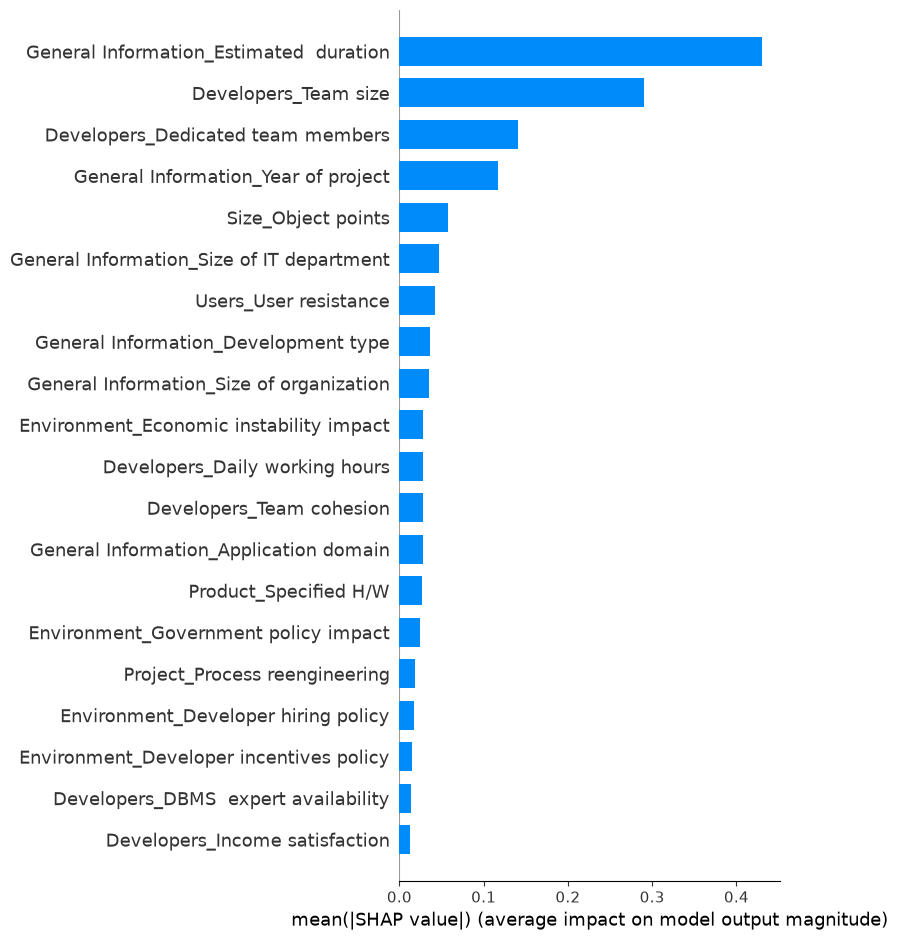

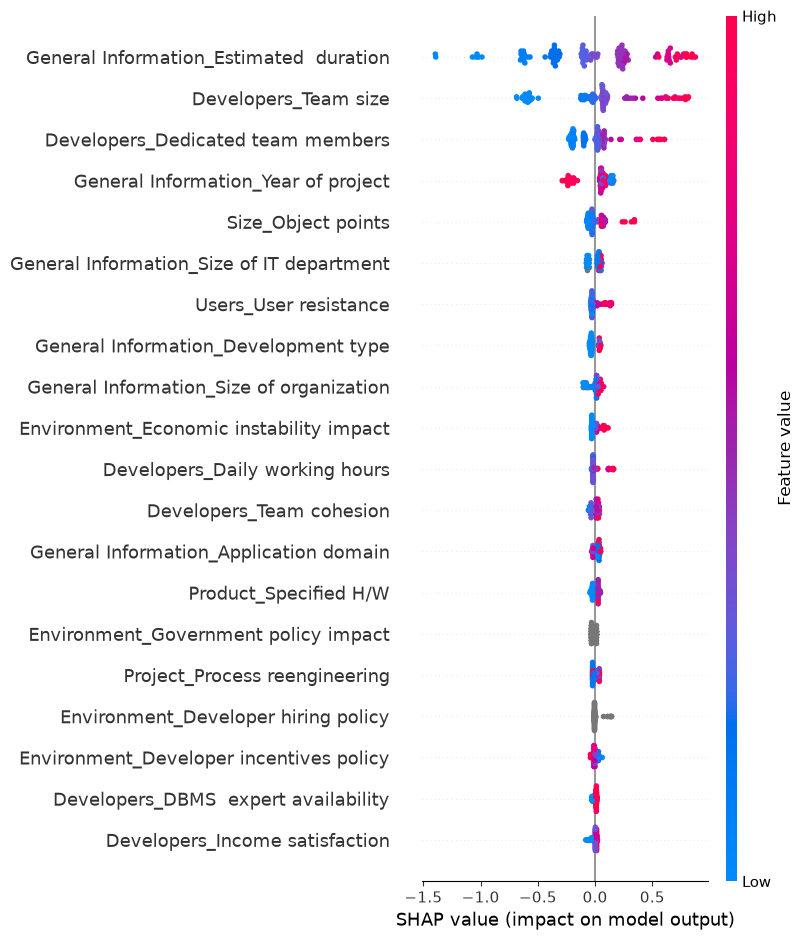

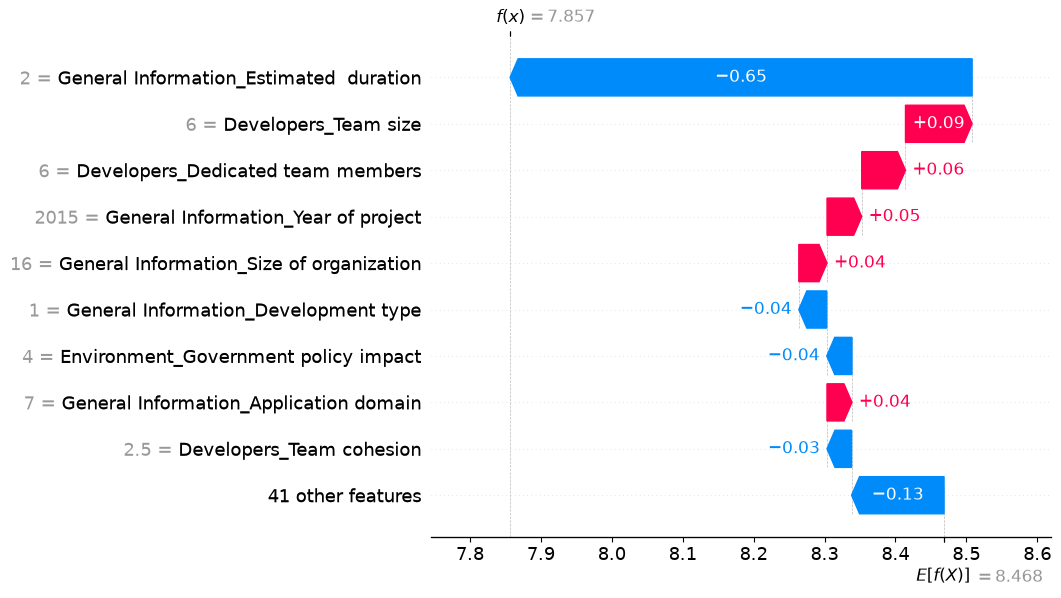

ValueError: continuous_features should be provided

In [ ]:
# Importing libraries
import shap
import dice_ml
import matplotlib.pyplot as plt


# Train final model on full Dataset for explaination   
# ندرّب نموذجًا نهائيًا على كامل البيانات لاستخدامه في التفسير
final_model = CatBoostRegressor(
    depth=final_params['depth'],
    learning_rate=final_params['learning_rate'],
    iterations=final_params['iterations'],
    l2_leaf_reg=final_params['l2_leaf_reg'],
    random_strength=final_params['random_strength'],
    bagging_temperature=final_params['bagging_temperature'],
    cat_features=cat_indices,
    loss_function='RMSE',
    random_seed=RANDOM_SEED,
    thread_count=-1,
    verbose=False,
    allow_writing_files=False
)

final_model.fit(X, y_log)
#print("Final model trained successfully")


 
# SHAP explination (global & local)
# استخدام TreeExplainer المخصص لـ CatBoost
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X)

# A. Global Summary Bar Plot (أهم الميزات بشكل عام)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, plot_type="bar", show=True)

# B. Global Beeswarm Plot (اتجاه تأثير كل ميزة على الجهد)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, show=True)

# C. Local Waterfall Plot (تفسير مشروع واحد محدد - المشروع رقم 0 مثلاً)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[0], show=True)


# ============================================================
# 3. COUNTERFACTUAL EXPLANATIONS (DiCE)
# ============================================================
# إعداد قائمة الميزات النصية والرقمية لـ DiCE
categorical_features = nominal_cat_cols
continuous_features = [col for col in X.columns if col not in categorical_features]

# دمج البيانات مع الهدف الأصلي لإعداد كائن DiCE
df_dice = X.copy()
df_dice['Effort_Actual_effort'] = y.values

# إعداد كائن البيانات والنموذج
 # 1. تجهيز الـ DataFrame
df_dice = X.copy()
df_dice['Effort_Actual_effort'] = y.values

# 2. تحديد الأعمدة المستمرة تلقائياً لتفادي الخطأ
continuous_features = [col for col in X.columns if col not in categorical_features]

# 3. إعداد كائن البيانات لـ DiCE
d = dice_ml.Data(
    dataframe=df_dice,
    continuous_feature_names=continuous_features,
    categorical_feature_names=categorical_features,
    outcome_name='Effort_Actual_effort'
)

# مغلف بسيط لتغطية التحويل اللوغاريتمي الذي استخدمه النموذج
class CatBoostDiCEWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, df):
        pred_log = self.model.predict(df)
        return np.clip(np.expm1(pred_log), 0, None)

m = dice_ml.Model(model=CatBoostDiCEWrapper(final_model), backend="sklearn", model_type="regressor")
exp = dice_ml.Dice(d, m, method="random")

# توليد سيناريوهات بديلة للمشروع رقم 0 (تقليل الجهد)
query_instance = X.iloc[[0]]
current_pred = np.expm1(final_model.predict(query_instance))[0]

print(f"\nCurrent Estimated Effort for Instance 0: {current_pred:.2f}")

# طلب سيناريوهات لخفض الجهد المستهدف بنسبة 20%
target_range = [current_pred * 0.5, current_pred * 0.8]

dice_exp = exp.generate_counterfactuals(
    query_instance, 
    total_CFs=2, 
    desired_range=target_range
)

# عرض النتيجة
dice_exp.visualize_as_dataframe()

In [1]:
# Importing libraries
import shap
import dice_ml
import numpy as np
import matplotlib.pyplot as plt

# 1. Train final model on full Dataset for explaination 
final_model = CatBoostRegressor(
    depth=final_params['depth'],
    learning_rate=final_params['learning_rate'],
    iterations=final_params['iterations'],
    l2_leaf_reg=final_params['l2_leaf_reg'],
    random_strength=final_params['random_strength'],
    bagging_temperature=final_params['bagging_temperature'],
    cat_features=cat_indices,
    loss_function='RMSE',
    random_seed=RANDOM_SEED,
    thread_count=-1,
    verbose=False,
    allow_writing_files=False
)

final_model.fit(X, y_log)
#print("Final model trained successfully for XAI Analysis")


#2. SHAP explination (global & local)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X)

# 2.1 Summary Bar Plot (Global)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, plot_type="bar", show=True)

# 2.2 Beeswarm Plot (Global)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, show=True)

# 2.3 Waterfall Plot(Local)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[0], show=True)


 
# 3.COUNTERFACTUAL explinations (DiCE)
df_dice = X.copy()
df_dice['Effort_Actual_effort'] = y.values

# Identifying categorical and continuous columns
categorical_features = nominal_cat_cols
continuous_features = [col for col in X.columns if col not in categorical_features]

# Object creation
d = dice_ml.Data(
    dataframe=df_dice,
    continuous_features=continuous_features,
    categorical_features=categorical_features,
    outcome_name='Effort_Actual_effort'
)

#
class CatBoostDiCEWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, df):
        pred_log = self.model.predict(df)
        return np.clip(np.expm1(pred_log), 0, None)

m = dice_ml.Model(model=CatBoostDiCEWrapper(final_model), backend="sklearn", model_type="regressor")
exp = dice_ml.Dice(d, m, method="random")

# توليد سيناريوهات بديلة للمشروع رقم 0
query_instance = X.iloc[[0]]
current_pred = np.expm1(final_model.predict(query_instance))[0]

print(f"\nCurrent Estimated Effort for Instance 0: {current_pred:.2f}")

 
target_range = [current_pred * 0.5, current_pred * 0.8]

dice_exp = exp.generate_counterfactuals(
    query_instance, 
    total_CFs=2, 
    desired_range=target_range
)

dice_exp.visualize_as_dataframe()

NameError: name 'CatBoostRegressor' is not defined